<a href="https://colab.research.google.com/github/rithikakknair/OIBSIP/blob/main/Python-lvl2-Task3-Credit-card/lvl2_Task3_Credit_card_ipnyb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve

from imblearn.over_sampling import SMOTE

# Load your specifically named dataset file
df = pd.read_csv('credit_card_fraud_detection.csv')

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (10000, 10)


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


Class Counts:
is_fraud
0    9849
1     151
Name: count, dtype: int64

Class Percentages:
is_fraud
0    98.49
1     1.51
Name: proportion, dtype: float64


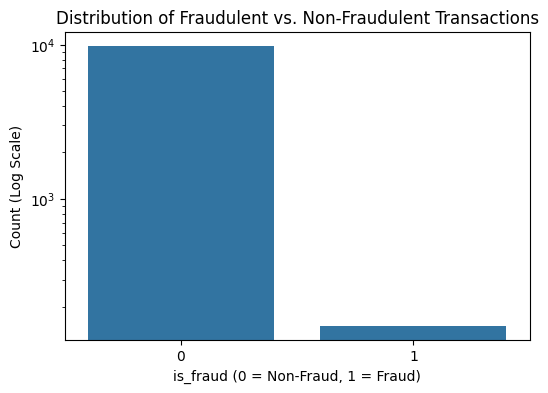

In [ ]:
# Check raw class counts and percentages using 'is_fraud'
class_counts = df['is_fraud'].value_counts()
class_percentages = df['is_fraud'].value_counts(normalize=True) * 100

print("Class Counts:")
print(class_counts)
print("\nClass Percentages:")
print(class_percentages)

# Visualizing class imbalance
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x='is_fraud', data=df)
plt.title('Distribution of Fraudulent vs. Non-Fraudulent Transactions')
plt.yscale('log') # Using log scale because of extreme imbalance
plt.xlabel('is_fraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('Count (Log Scale)')
plt.show()

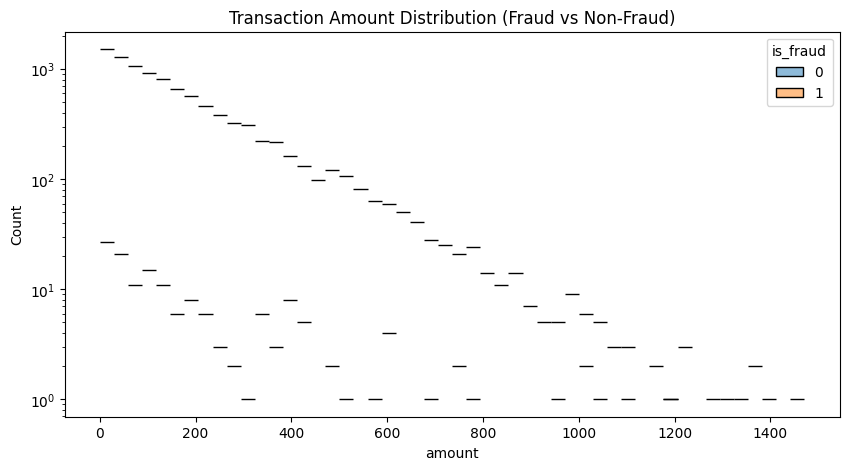

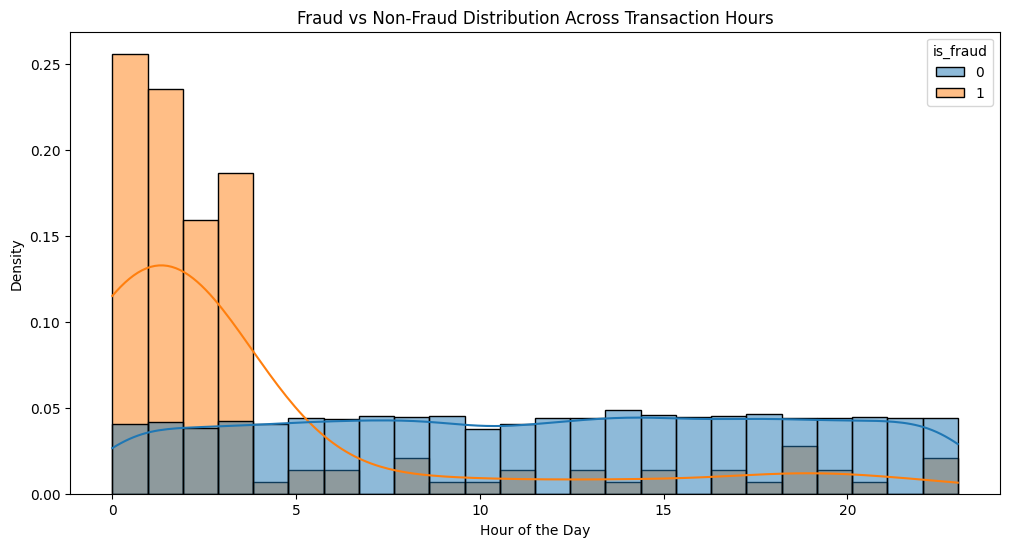

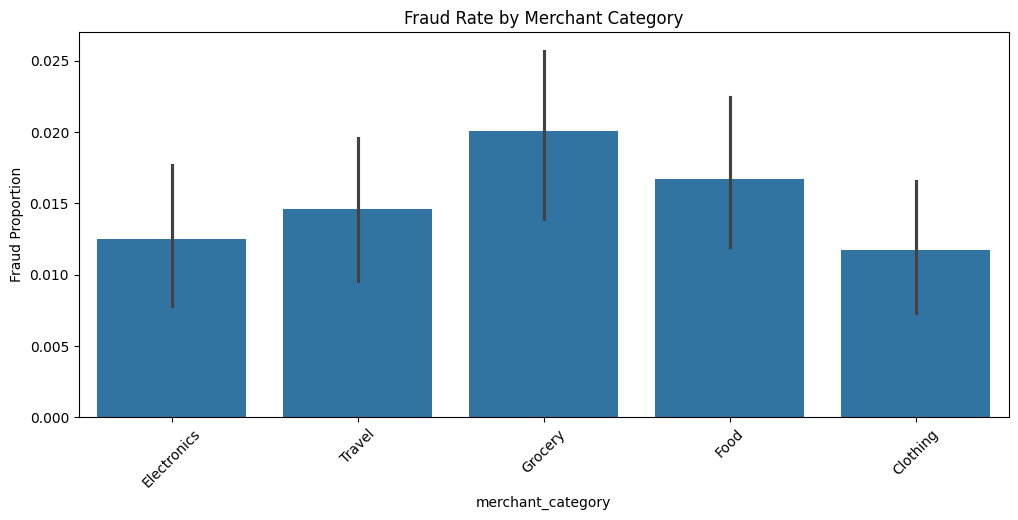

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of Transaction Amounts for Fraud vs Non-Fraud
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='amount', hue='is_fraud', bins=50, log_scale=(False, True), common_norm=False)
plt.title('Transaction Amount Distribution (Fraud vs Non-Fraud)')
plt.show()

# 2. Transaction Hour Analysis
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='transaction_hour', hue='is_fraud', bins=24, common_norm=False, stat="density", kde=True)
plt.title('Fraud vs Non-Fraud Distribution Across Transaction Hours')
plt.xlabel('Hour of the Day')
plt.show()

# 3. Fraud rate by Merchant Category
plt.figure(figsize=(12, 5))
sns.barplot(data=df, x='merchant_category', y='is_fraud', estimator=lambda x: sum(x)/len(x))
plt.title('Fraud Rate by Merchant Category')
plt.xticks(rotation=45)
plt.ylabel('Fraud Proportion')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import pandas as pd

# 1. Drop transaction_id as it doesn't help predict fraud
df_model = df.drop(columns=['transaction_id'])

# 2. One-hot encode categorical features (like merchant_category)
df_model = pd.get_dummies(df_model, columns=['merchant_category'], drop_first=True)

# 3. Separate features (X) and target (y)
X = df_model.drop(columns=['is_fraud'])
y = df_model['is_fraud']

# 4. Stratified Train/Test Split (ensures fraud cases appear proportionally in both splits)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Before SMOTE - Training set shape: {X_train.shape}, Fraud cases: {y_train.sum()}")

# 5. Apply SMOTE ONLY on the training data to prevent data leakage
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"After SMOTE - Training set shape: {X_train_smote.shape}, Fraud cases: {y_train_smote.sum()}")

Before SMOTE - Training set shape: (8000, 11), Fraud cases: 121
After SMOTE - Training set shape: (15758, 11), Fraud cases: 7879


Training Logistic Regression...
Training Random Forest...

=== Logistic Regression Performance ===
              precision    recall  f1-score   support

           0     0.9989    0.9249    0.9605      1970
           1     0.1591    0.9333    0.2718        30

    accuracy                         0.9250      2000
   macro avg     0.5790    0.9291    0.6162      2000
weighted avg     0.9863    0.9250    0.9501      2000

ROC-AUC Score: 0.9830


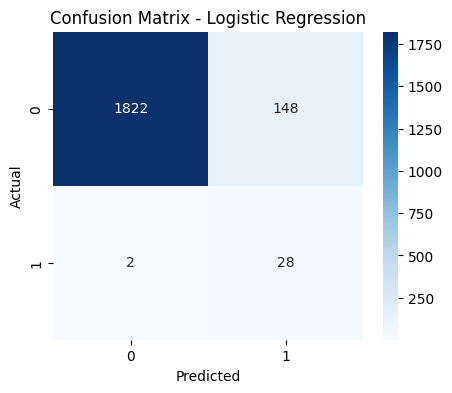


=== Random Forest Performance ===
              precision    recall  f1-score   support

           0     0.9959    0.9863    0.9911      1970
           1     0.4490    0.7333    0.5570        30

    accuracy                         0.9825      2000
   macro avg     0.7224    0.8598    0.7740      2000
weighted avg     0.9877    0.9825    0.9846      2000

ROC-AUC Score: 0.9868


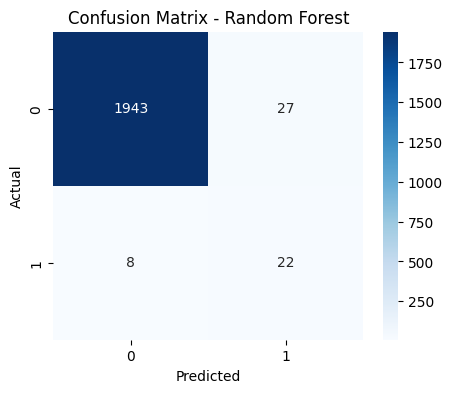

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Train Model 1: Logistic Regression
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_smote, y_train_smote)
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

# 2. Train Model 2: Random Forest Classifier
print("Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# 3. Evaluation Function
def evaluate_model(y_true, y_pred, y_prob, model_name):
    print(f"\n=== {model_name} Performance ===")
    print(classification_report(y_true, y_pred, digits=4))
    print(f"ROC-AUC Score: {roc_auc_score(y_true, y_prob):.4f}")

    # Confusion Matrix
    plt.figure(figsize=(5, 4))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Evaluate both models
evaluate_model(y_test, y_pred_lr, y_prob_lr, "Logistic Regression")
evaluate_model(y_test, y_pred_rf, y_prob_rf, "Random Forest")

In [ ]:
import pandas as pd

# 1. Logistic Regression Coefficients (Drivers of Fraud)
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_[0]
})
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()

print("Top Logistic Regression Drivers of Fraud:")
print(coefficients.sort_values(by='Abs_Coefficient', ascending=False).head(10))

# 2. Random Forest Feature Importances
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

print("\nTop Random Forest Feature Importances:")
print(importances.sort_values(by='Importance', ascending=False).head(10))

Top Logistic Regression Drivers of Fraud:
                          Feature  Coefficient  Abs_Coefficient
10       merchant_category_Travel     3.689530         3.689530
8          merchant_category_Food     3.668736         3.668736
9       merchant_category_Grocery     3.661160         3.661160
7   merchant_category_Electronics     3.119102         3.119102
3               location_mismatch     2.773927         2.773927
2             foreign_transaction     2.770472         2.770472
5               velocity_last_24h     0.766144         0.766144
1                transaction_hour    -0.327511         0.327511
4              device_trust_score    -0.130046         0.130046
6                  cardholder_age    -0.009924         0.009924

Top Random Forest Feature Importances:
                      Feature  Importance
4          device_trust_score    0.302605
1            transaction_hour    0.256955
0                      amount    0.089083
5           velocity_last_24h    0.077334
9   

### Why Standard Accuracy is Misleading for Fraud Detection
In heavily imbalanced datasets like this one, fraudulent transactions represent a tiny fraction of the total data (roughly 0.17%). If a model is lazy and simply predicts "non-fraud" for every single transaction, it will achieve an accuracy of approximately 99.83%.

While 99.83% sounds exceptional on paper, the model completely fails its primary objective: catching fraudulent transactions. Accuracy masks minority class performance because it treats all errors equally, making it a dangerous metric for fraud detection. Instead, we must rely on evaluation metrics that focus on the minority class, such as Precision, Recall, F1-Score, and ROC-AUC.

### Recall vs. Precision Trade-off in Fraud Detection
When evaluating our models, *Recall* is generally considered the most critical metric for fraud detection.
- *Recall (False Negatives):* Missing a fraudulent transaction means direct financial loss, security breaches, and potential liability. High recall ensures we catch as many actual fraud cases as possible.
- *Precision (False Positives):* However, maximizing recall can sometimes increase false positives—flagging legitimate transactions and blocking valid customer cards. This hurts user experience.

Therefore, the ideal pipeline balances a high *Recall* to catch fraud while maintaining an acceptable *Precision* level to minimize false alarms. Adjusting the decision threshold allows us to fine-tune this trade-off based on business risk tolerance.

### Scalability Discussion: Handling 1 Million Transactions per Hour
To scale this machine learning pipeline to handle *1 million transactions per hour* (approx. 277 transactions per second), a real-time streaming and distributed architecture is required:
1. *Data Ingestion & Streaming:* Transition from batch CSV processing to a real-time event streaming platform like *Apache Kafka* or *AWS Kinesis* to ingest transactions as they happen.
2. *Feature Store:* Use a low-latency feature store (like Feast or Redis) to instantly pull user historical features (e.g., velocity in the last 24 hours) for real-time scoring.
3. *Model Serving & Inference:* Deploy the trained model (such as Random Forest or XGBoost converted to optimized formats like ONNX) inside containerized microservices (e.g., Docker & Kubernetes) or cloud endpoints (AWS SageMaker) to deliver predictions in milliseconds.
4. *Distributed Computing:* For heavy batch retraining pipelines, use *PySpark* or cloud-native data warehouses (like Snowflake or BigQuery) to handle massive scale.